In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import Rectangle

In [ ]:
dt = 0.01
seed = 123
N = 10000

rng = np.random.default_rng(seed)

#definimos la distribución con sus parámetros y el número de samples
v = rng.normal(loc= 0, scale = 1, size = N)
w = v * np.sqrt(dt)

dW = np.sqrt(dt) * v #incremento
W = np.insert(np.cumsum(dW), 0, 0) # camino a partir de la suma de incrementos iid

print(W)

[ 0.         -0.09891214 -0.1356908  ...  8.35179298  8.20433368
  8.23768158]


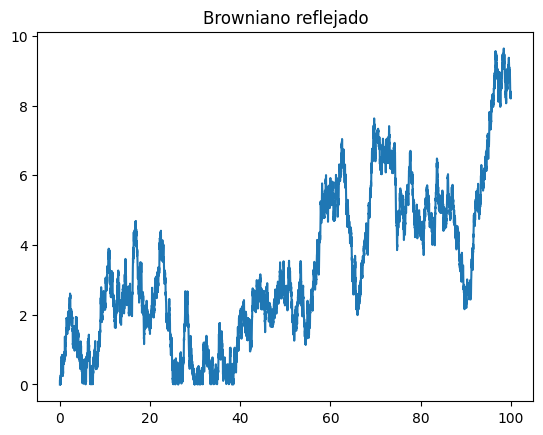

In [ ]:
X_reflejado = np.abs(W)
T = dt * N
t = np.linspace(0, T, N+1)



plt.title("Browniano reflejado")
plt.plot(t, X_reflejado)

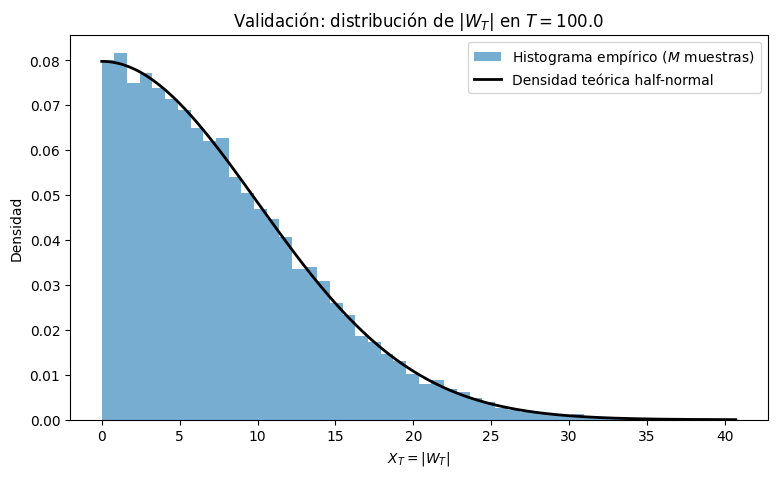

In [ ]:
M = 20000           # número de realizaciones independientes
rng_val = np.random.default_rng(456)   # generador nuevo, para no interferir con el de antes

WT_samples = rng_val.normal(0, np.sqrt(T), size=M)
XT_samples = np.abs(WT_samples)        # reflexión: aplicar valor absoluto

# histograma empírico
plt.figure(figsize=(9,5))
plt.hist(XT_samples, bins=50, density=True, alpha=0.6, label="Histograma empírico ($M$ muestras)")

# densidad teórica half-normal
x_vals = np.linspace(0, XT_samples.max(), 200)
densidad_teorica = (2/np.sqrt(2*np.pi*T)) * np.exp(-x_vals**2/(2*T))
plt.plot(x_vals, densidad_teorica, color="black", lw=2, label="Densidad teórica half-normal")

plt.xlabel("$X_T = |W_T|$")
plt.ylabel("Densidad")
plt.title(f"Validación: distribución de $|W_T|$ en $T={T}$")
plt.legend()
plt.show()

$$
 W_{i+1} = W_{i} + \sqrt{\delta} Z
$$

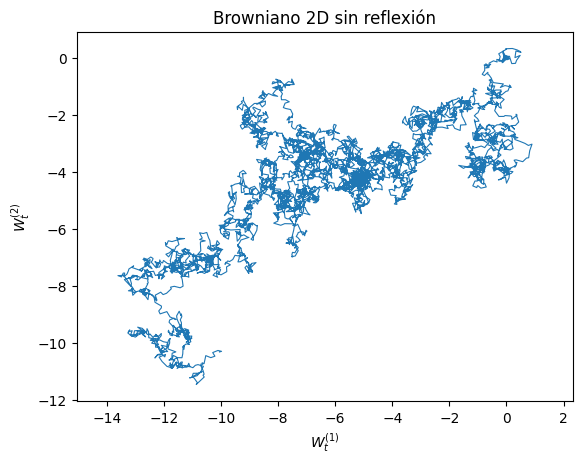

In [ ]:
#Browniano en 2 dimensiones
N = 5000
dt = 0.01
T = dt * N
t = np.linspace(0, T, N+1)

rng2 = np.random.default_rng(789)
Z = rng2.normal(0, 1, size = (2, N)) # definimos una normal 2D
dW = np.sqrt(dt) * Z

W = np.cumsum(dW, axis=1)              # forma (2, N)
W = np.insert(W, 0, [0, 0], axis=1)    # forma (2, N+1), con columna inicial = origen

plt.plot(W[0,:], W[1,:], lw=0.8)
plt.xlabel("$W^{(1)}_t$")
plt.ylabel("$W^{(2)}_t$")
plt.title("Browniano 2D sin reflexión")
plt.axis("equal")   # importante: misma escala en ambos ejes
plt.show()


[ 2. -1.]


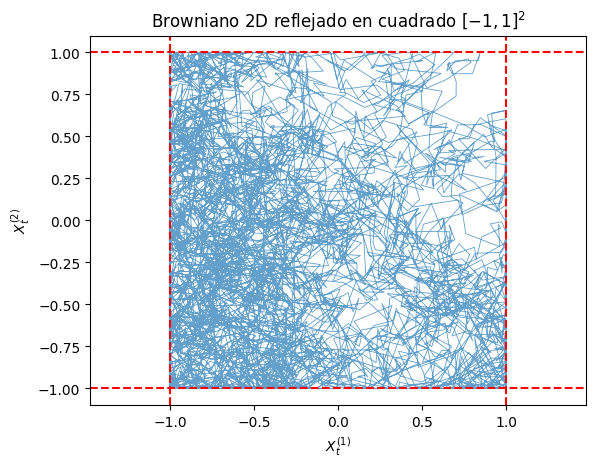

In [ ]:
#proyectamos el proceso dentro de 1 cuadrado

def proy_cuadrado(x, L):
  x1_proy = np.clip(x[0], -L, L)
  x2_proy = np.clip(x[1], -L, L)
  return np.array([x1_proy, x2_proy])

print(proy_cuadrado([3.0, -1.0], 2))

L = 1   # el cuadrado es [-1.5, 1.5] x [-1.5, 1.5]

X_reflejado_2d = np.zeros((2, N+1))
X_reflejado_2d[:, 0] = np.array([0.0, 0.0])   # condición inicial: origen

for n in range(N):
    paso_libre = X_reflejado_2d[:, n] + dW[:, n]    # Euler-Maruyama sin restricción (drift=0 acá)
    X_reflejado_2d[:, n+1] = proy_cuadrado(paso_libre, L)   # aplicá la proyección sobre paso_libre


plt.plot(X_reflejado_2d[0,:], X_reflejado_2d[1,:], lw=0.6, alpha=0.7)
plt.axhline(L, color="red", linestyle="--")
plt.axhline(-L, color="red", linestyle="--")
plt.axvline(L, color="red", linestyle="--")
plt.axvline(-L, color="red", linestyle="--")

plt.xlabel("$X^{(1)}_t$")
plt.ylabel("$X^{(2)}_t$")
plt.title(f"Browniano 2D reflejado en cuadrado $[-{L},{L}]^2$")
plt.axis("equal")
plt.show()

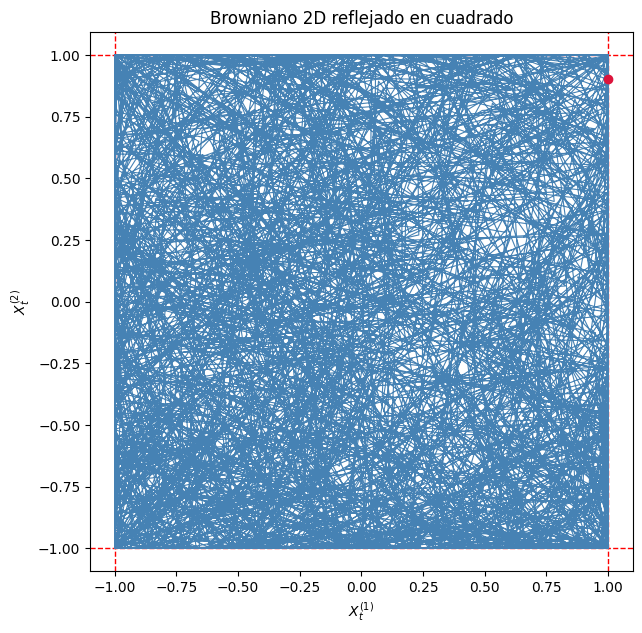

In [ ]:
fig, ax = plt.subplots(figsize=(7,7))
ax.set_xlim(-L-0.3, L+0.3)
ax.set_ylim(-L-0.3, L+0.3)
ax.set_xlabel("$X^{(1)}_t$")
ax.set_ylabel("$X^{(2)}_t$")
ax.set_title("Browniano 2D reflejado en cuadrado")
ax.axis("equal")

# líneas de referencia del cuadrado
ax.axhline(L, color="red", linestyle="--", lw=1)
ax.axhline(-L, color="red", linestyle="--", lw=1)
ax.axvline(L, color="red", linestyle="--", lw=1)
ax.axvline(-L, color="red", linestyle="--", lw=1)

line, = ax.plot([], [], lw=0.8, color="steelblue")
point, = ax.plot([], [], "o", color="crimson", markersize=6)

def init():
    line.set_data([], [])
    point.set_data([], [])
    return line, point

steps_per_frame = 10
n_frames = N // steps_per_frame

def update(frame):
    idx = (frame + 1) * steps_per_frame
    line.set_data(X_reflejado_2d[0, :idx], X_reflejado_2d[1,:idx])
    point.set_data([X_reflejado_2d[0, idx-1]], [X_reflejado_2d[1, idx-1]])
    return line, point

ani = animation.FuncAnimation(
    fig, update, frames=n_frames, init_func=init,
    blit=True, interval=30
)

ani.save("rebote_cuadrado.gif", writer="pillow", fps=30, dpi = 120)


Tenemos la RSDE "reflecting stochastic differential equation"

$$
 X_{t+1} =  P _{G}\{ X_{t} + b(t, X_t) dt + \sigma(t, X_t) d W_t\}
$$

donde el conjunto convexo $G$ esta dado por:
$$
    G = [-L, L]^2
$$
pero al ser un conjunto movil, consideramos a $C(t) = (c_1(t), c_2(t))$, por lo que:
$$
    G(t) = G + C(t)
$$

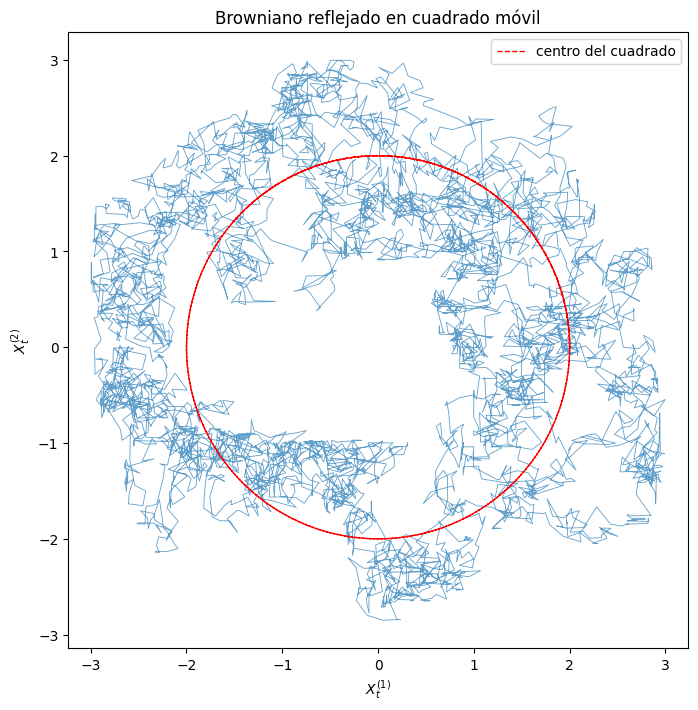

In [ ]:
from re import X
A = 2.0
omega = 0.3
bx, by = 0.0, 0.0
sigma = 0.35


#trayectoria del centro del cuadrado
c1 = A * np.cos(omega * t)
c2 = A * np.sin(omega * t)

#calculamos la proyección para cada t
def proy_cuadrado_movil(x, L, centro):
    x1_proy = np.clip(x[0], centro[0] - L, centro[0] + L)
    x2_proy = np.clip(x[1], centro[1] - L, centro[1] + L)
    return np.array([x1_proy, x2_proy])

L = 1.0
X_movil = np.zeros((2, N+1))
X_movil[:, 0] = np.array([c1[0], c2[0]])   # partimos en el centro inicial del cuadrado

def drift(X_movil):
  return np.array([bx, by])

def diffusion(X_movil):
  return sigma

for n in range(N):
    centro_actual = np.array([c1[n], c2[n]])
    paso_libre = X_movil[:, n] + drift(X_movil) * dt + dW[:, n]
    X_movil[:, n+1] = proy_cuadrado_movil(paso_libre, L, centro_actual)

plt.figure(figsize=(8,8))
plt.plot(X_movil[0,:], X_movil[1,:], lw=0.6, alpha=0.7)
plt.plot(c1, c2, color="red", linestyle="--", lw=1, label="centro del cuadrado")
plt.xlabel("$X^{(1)}_t$")
plt.ylabel("$X^{(2)}_t$")
plt.title("Browniano reflejado en cuadrado móvil")
plt.axis("equal")
plt.legend()
plt.savefig("trayectoria final.png", dpi= 300)
plt.show()


In [ ]:
print(X_movil)

[[ 2.          2.30877709  1.85035942 ...  0.77627241  0.7796841
   0.81189357]
 [ 0.         -0.47338477 -0.32912877 ... -1.85913788 -2.1789874
  -2.50195432]]


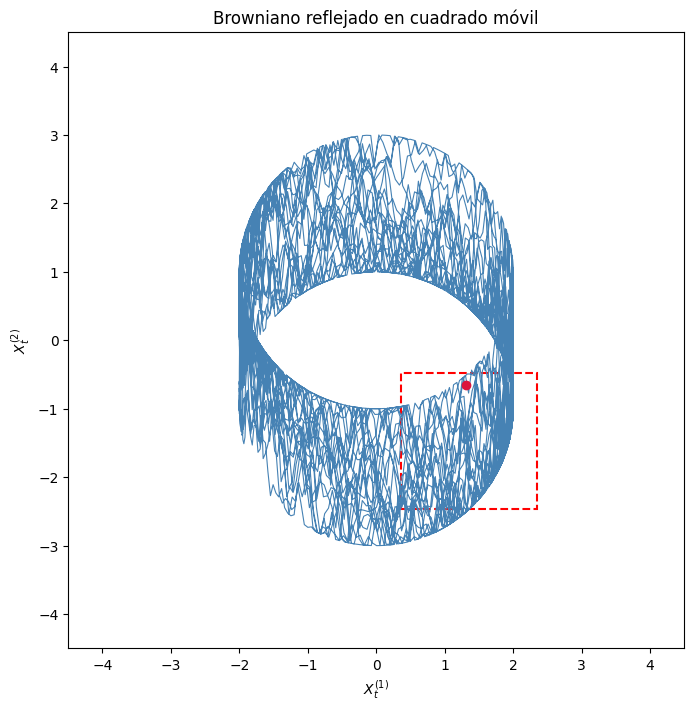

In [ ]:
fig, ax = plt.subplots(figsize=(8,8))

margen = 1.5
lim = A + L + margen
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("$X^{(1)}_t$")
ax.set_ylabel("$X^{(2)}_t$")
ax.set_title("Browniano reflejado en cuadrado móvil")
ax.axis("equal")

ax.set_aspect("equal", adjustable="box")
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)

# rectángulo inicial, en la posición del centro en t=0
rect = Rectangle(
    (c1[0]-L, c2[0]-L), 2*L, 2*L,
    fill=False, edgecolor="red", linestyle="--", lw=1.5
)
ax.add_patch(rect)

line, = ax.plot([], [], lw=0.8, color="steelblue")
point, = ax.plot([], [], "o", color="crimson", markersize=6)

def init():
    line.set_data([], [])
    point.set_data([], [])
    rect.set_xy((c1[0]-L, c2[0]-L))
    return line, point, rect

steps_per_frame = 10
n_frames = N // steps_per_frame

def update(frame):
    idx = (frame + 1) * steps_per_frame
    line.set_data(X_movil[0, :idx], X_movil[1, :idx])
    point.set_data([X_movil[0, idx-1]], [X_movil[1, idx-1]])
    rect.set_xy((c1[idx-1] - L, c2[idx-1] - L))
    return line, point, rect

ani = animation.FuncAnimation(
    fig, update, frames=n_frames, init_func=init,
    blit=True, interval=30
)

ani.save("cuadrado_movil.gif", writer="pillow", fps=30, dpi=100)

In [ ]:
salto = 0.5
t_escalon = np.floor(t/salto) * salto

c1 = A * np.cos(omega * t_escalon)
c2 = A * np.sin(omega * t_escalon)



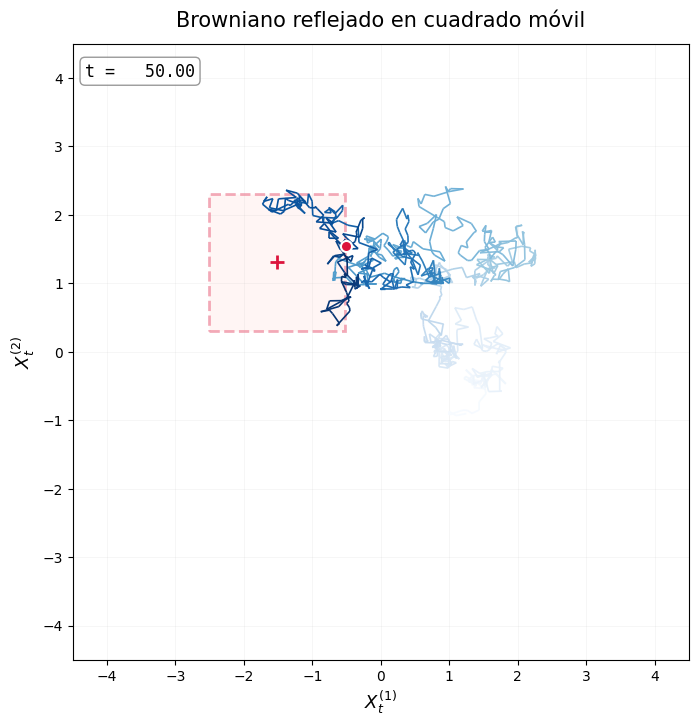

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import Rectangle
from matplotlib.collections import LineCollection

# ---------- Figura ----------
fig, ax = plt.subplots(figsize=(8, 8), dpi=100)
fig.patch.set_facecolor("white")

margen = 1.5
lim = A + L + margen
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_aspect("equal", adjustable="box")   # una sola vez; 'axis("equal")' era redundante
ax.set_xlabel("$X^{(1)}_t$", fontsize=13)
ax.set_ylabel("$X^{(2)}_t$", fontsize=13)
ax.grid(alpha=0.15, lw=0.5)
ax.set_title("Browniano reflejado en cuadrado móvil", fontsize=15, pad=12)

# ---------- Elementos ----------
rect = Rectangle((c1[0]-L, c2[0]-L), 2*L, 2*L,
                 fill=True, facecolor="mistyrose", alpha=0.35,
                 edgecolor="crimson", linestyle="--", lw=2, zorder=1)
ax.add_patch(rect)

# Estela con desvanecimiento: LineCollection en vez de Line2D
trail = LineCollection([], cmap="Blues", lw=1.2, zorder=2)
ax.add_collection(trail)

point, = ax.plot([], [], "o", color="crimson", ms=8,
                 mec="white", mew=1.5, zorder=4)
centro, = ax.plot([], [], "+", color="crimson", ms=10, mew=2, zorder=3)

# Reloj y contador
reloj = ax.text(0.02, 0.97, "", transform=ax.transAxes,
                fontsize=12, va="top", family="monospace",
                bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.8))

trail_len = 800          # nº de pasos visibles de la estela

def segmentos(x, y):
    pts = np.array([x, y]).T.reshape(-1, 1, 2)
    return np.concatenate([pts[:-1], pts[1:]], axis=1)

def init():
    trail.set_segments([])
    point.set_data([], [])
    centro.set_data([], [])
    rect.set_xy((c1[0]-L, c2[0]-L))
    reloj.set_text("")
    return trail, point, centro, rect, reloj

steps_per_frame = 10
n_frames = N // steps_per_frame

def update(frame):
    idx = (frame + 1) * steps_per_frame
    i0 = max(0, idx - trail_len)               # ventana deslizante

    segs = segmentos(X_movil[0, i0:idx], X_movil[1, i0:idx])
    trail.set_segments(segs)
    trail.set_array(np.linspace(0.2, 1.0, len(segs)))  # gradiente: viejo→pálido

    point.set_data([X_movil[0, idx-1]], [X_movil[1, idx-1]])
    centro.set_data([c1[idx-1]], [c2[idx-1]])
    rect.set_xy((c1[idx-1]-L, c2[idx-1]-L))
    reloj.set_text(f"t = {idx*dt:7.2f}")
    return trail, point, centro, rect, reloj

ani = animation.FuncAnimation(fig, update, frames=n_frames,
                              init_func=init, blit=True, interval=30)

# MP4 pesa ~10x menos que GIF y se ve mejor en diapositivas
try:
    ani.save("cuadrado_movil.mp4", writer="ffmpeg", fps=30, dpi=150,
             savefig_kwargs={"facecolor": "white"})
except (FileNotFoundError, RuntimeError):
    ani.save("cuadrado_movil.gif", writer="pillow", fps=30, dpi=100)